# 3. Исследовательский анализ рынка

**Популяция:** январь–сентябрь 2019 года; внутренний рынок — записи, где регион не «Экспорт». Все доли относятся к очищенному источнику, а не к внешней официальной статистике. Полная база с экспортом показана отдельно.

**Метрики:** продажи нетто = сумма количества с возвратами; продажи в USD = сумма итоговой стоимости с возвратами. Средняя стоимость проданного автомобиля = сумма положительных продаж / количество положительно проданных автомобилей. Это прокси среднего чека на автомобиль: идентификатора заказа нет. Для распределений веса равны количеству, возвраты исключены. Неизвестные категории включены в знаменатель.

Девять месяцев одного года позволяют описать динамику внутри периода, но не доказать сезонность или годовой рост.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

# Тетради можно открывать из папки проекта или из coursework.
ROOT = Path.cwd() if Path('clean_data.py').exists() else Path.cwd() / 'coursework'
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)
from clean_data import load_raw, normalize, aggregate_clean, read_clean, run, validate, CATEGORIES, DROP, COMPANIES, MONTHS
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

import matplotlib.pyplot as plt
from analysis_utils import setup, metrics, breakdown, compare, expanded_values, save_figure, bar, BLUE, GOLD
setup()
df = read_clean('data/autokz2019_clean.csv')
market = df.loc[~df.is_export].copy()
mercur = market.loc[market.company.eq('Mercur Auto')].copy()
positive = market.loc[market.quantity.gt(0)].copy()
Path('tables').mkdir(exist_ok=True)

kpi = pd.DataFrame({'Вся база': metrics(df), 'Внутренний рынок': metrics(market),
                    'Экспорт': metrics(df.loc[df.is_export])}).T
display(kpi)
kpi.to_csv('tables/market_kpi.csv', encoding='utf-8-sig')


,net_units,gross_units,returned_units,net_sales_usd,gross_sales_usd,avg_vehicle_usd
Вся база,"35,165.00","35,166.00",1.00,"815,179,587.19","815,215,175.44","23,181.91"
Внутренний рынок,"34,725.00","34,726.00",1.00,"801,697,865.97","801,733,454.22","23,087.41"
Экспорт,440.00,440.00,0.00,"13,481,721.22","13,481,721.22","30,640.28"


## Динамика по месяцам
Показываем одновременно объём в автомобилях и сумму продаж; это разные показатели.

,units,sales_usd,mom_pct
sale_date,,,
2019-01-31,2953,"67,443,577.91",<NA>
2019-02-28,3193,"69,570,790.28",8.13
2019-03-31,3437,"79,726,412.64",7.64
2019-04-30,4282,"98,131,069.72",24.59
2019-05-31,4257,"104,823,982.76",-0.58
2019-06-30,4177,"98,883,773.76",-1.88
2019-07-31,4432,"102,384,394.30",6.10
2019-08-31,4250,"95,117,393.75",-4.11
2019-09-30,3744,"85,616,470.84",-11.91


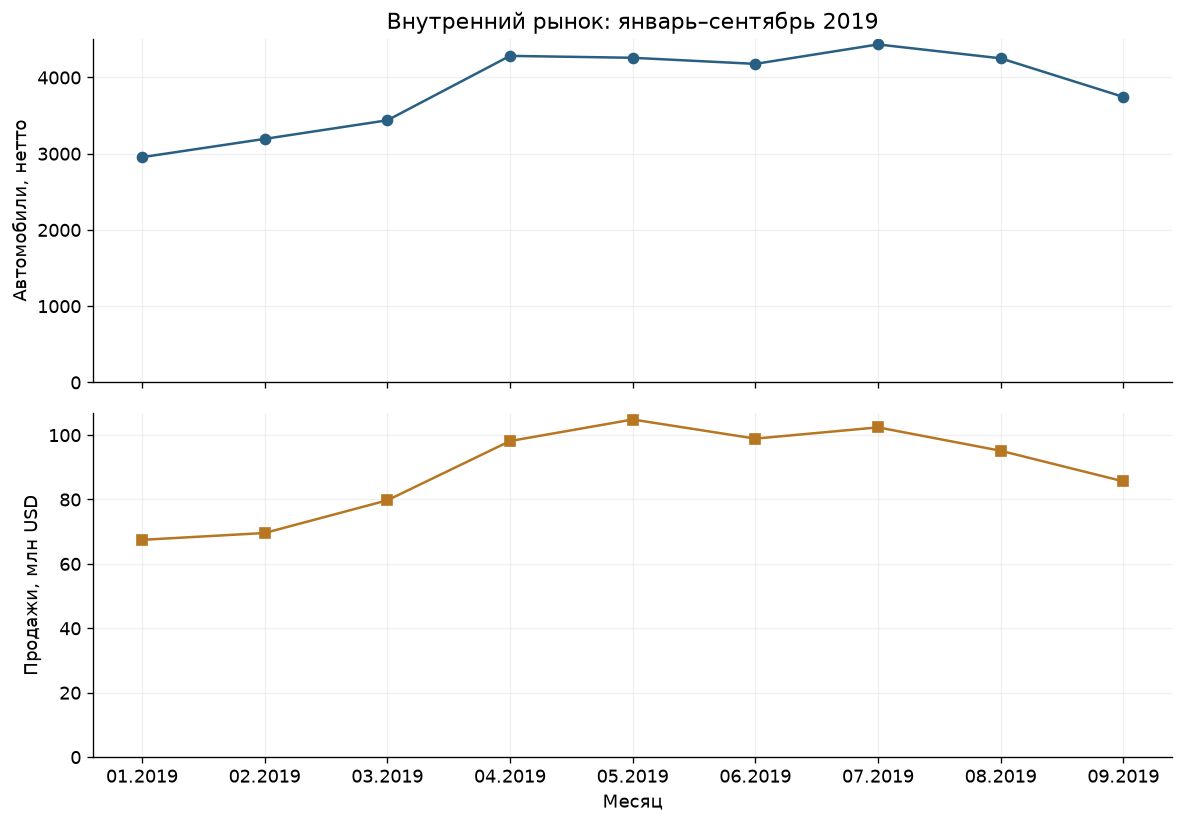

Пик: 07.2019, 4,432 автомобилей; изменение сентябрь/январь: 26.8%.


In [2]:
monthly = market.groupby('sale_date').agg(units=('quantity', 'sum'), sales_usd=('total_sales_usd', 'sum'))
monthly['mom_pct'] = monthly.units.pct_change() * 100
display(monthly)
monthly.to_csv('tables/market_monthly.csv')
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
labels = monthly.index.strftime('%m.%Y')
axes[0].plot(labels, monthly.units, marker='o', color=BLUE)
axes[0].set(title='Внутренний рынок: январь–сентябрь 2019', ylabel='Автомобили, нетто', ylim=(0, None))
axes[1].plot(labels, monthly.sales_usd / 1e6, marker='s', color=GOLD)
axes[1].set(ylabel='Продажи, млн USD', xlabel='Месяц', ylim=(0, None))
save_figure('01_market_monthly')
print(f'Пик: {monthly.units.idxmax():%m.%Y}, {monthly.units.max():,} автомобилей; изменение сентябрь/январь: {(monthly.units.iloc[-1]/monthly.units.iloc[0]-1)*100:.1f}%.')

## Бренды и модели
Ранжирование строится по сумме количества, а не по числу записей.

,units,sales_usd,share_pct
brand,,,
Lada,11085,"107,766,678.95",31.92
Hyundai,4987,"113,312,775.37",14.36
Toyota,3636,"149,926,065.91",10.47
Kia,2346,"45,415,000.00",6.76
Nissan,1651,"39,722,742.33",4.75
GAZ,1361,"23,823,190.94",3.92
UAZ,1217,"16,900,203.14",3.50
Renault,1193,"16,066,018.10",3.44
Volkswagen,1048,"21,654,010.18",3.02


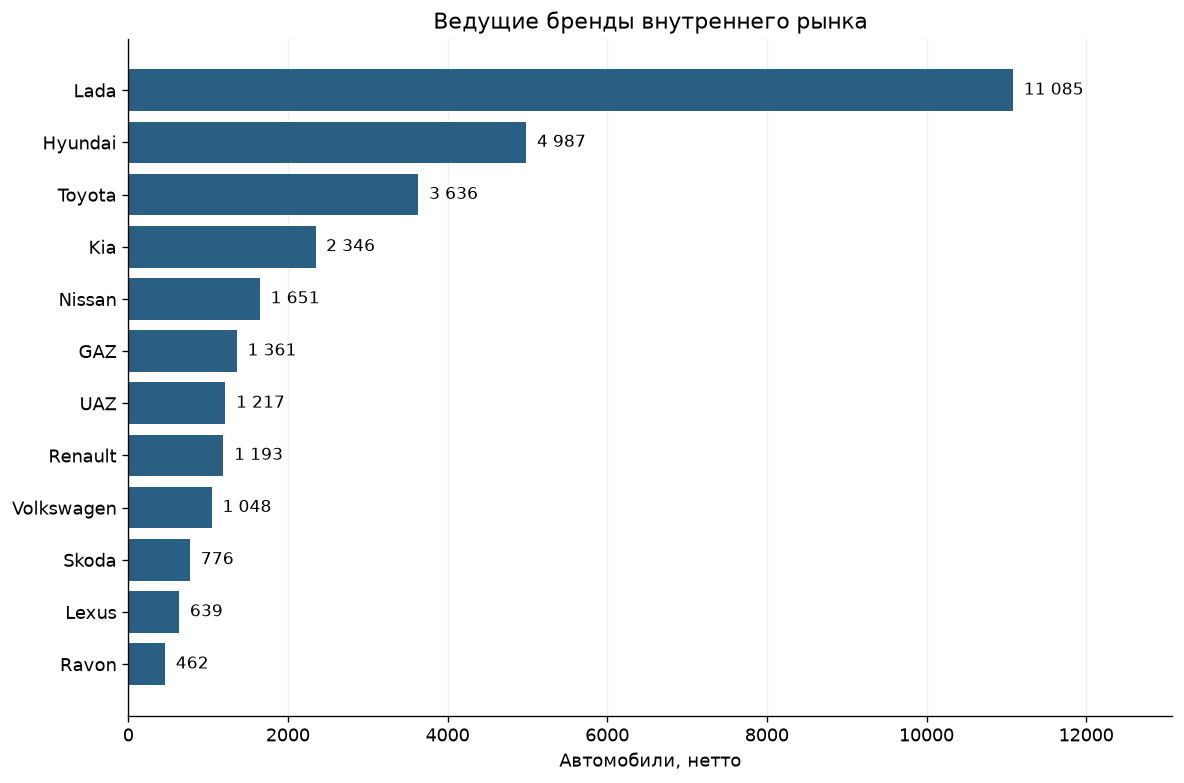

Три крупнейших бренда дают 56.8% объёма.


In [3]:
brands = breakdown(market, 'brand')
display(brands.head(12))
brands.to_csv('tables/market_brands.csv', encoding='utf-8-sig')
bar(brands.units.head(12), 'Ведущие бренды внутреннего рынка', 'Автомобили, нетто', '02_brands')
print(f'Три крупнейших бренда дают {brands.share_pct.head(3).sum():.1f}% объёма.')

,units,sales_usd,share_pct
brand_model,,,
Lada Granta,3663,"26,664,805.26",10.55
Lada Vesta,2650,"31,081,473.68",7.63
Lada 4x4,2469,"22,338,600.00",7.11
Lada Largus,1682,"19,161,900.00",4.84
Hyundai Tucson,1370,"36,314,314.26",3.95
Hyundai Accent,1246,"20,837,341.39",3.59
Toyota Camry,1120,"37,396,000.00",3.23
Hyundai Creta,1054,"21,112,880.07",3.04
Kia Rio,993,"13,755,500.00",2.86


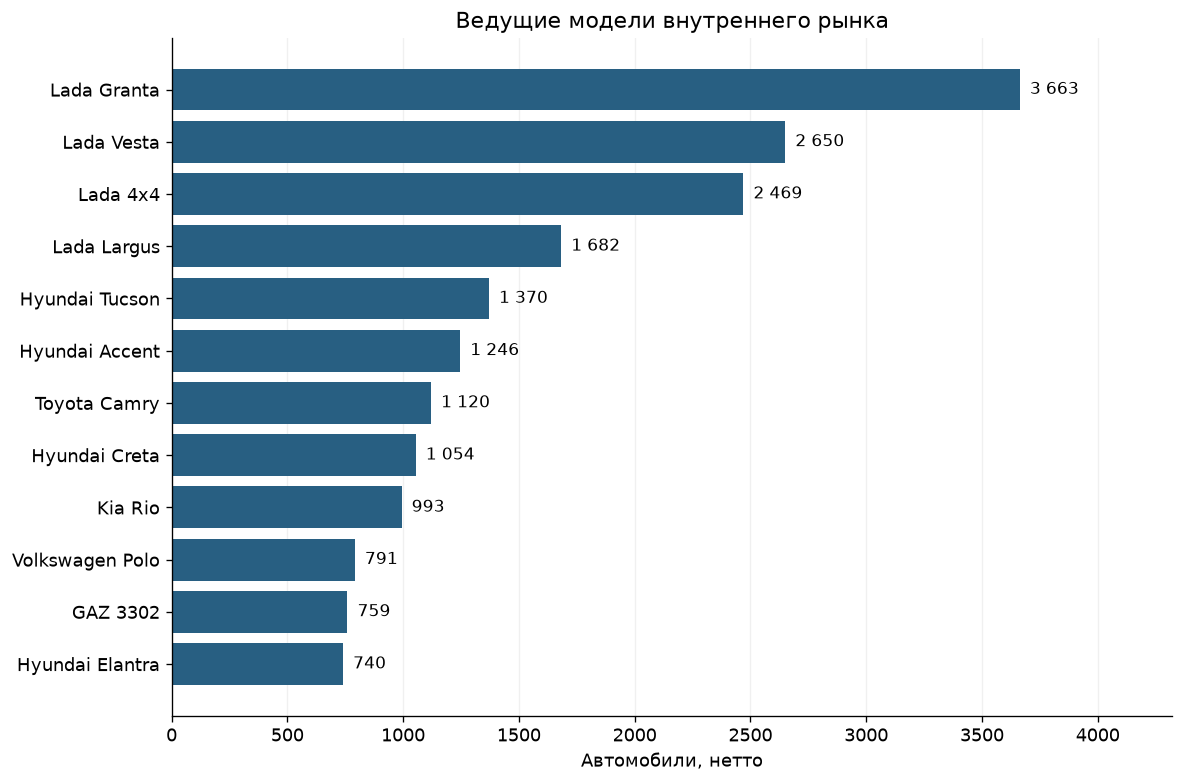

In [4]:
model_data = market.assign(brand_model=market.brand + ' ' + market.model)
models = breakdown(model_data, 'brand_model')
display(models.head(12))
models.to_csv('tables/market_models.csv', encoding='utf-8-sig')
bar(models.units.head(12), 'Ведущие модели внутреннего рынка', 'Автомобили, нетто', '03_models')

**Интерпретация.** Лидер по моделям — Lada Granta: 3 663 автомобиля (10.55% внутреннего объёма). Далее идут Lada Vesta и Lada 4x4. Преобладание Lada в рейтинге моделей согласуется с лидерством бренда; число записей здесь не использовано как вес.

## География и сегменты
«Регион» в этом источнике преимущественно обозначает город. «Область» рассматривается отдельно; названия сохранены в историческом виде.

,units,sales_usd,share_pct
area,,,
Г.Алматы,7682,"240,248,212.74",22.12
Г.Нур-Султан,5682,"154,143,367.05",16.36
Восточно-Казахстанская Область,2658,"54,034,104.38",7.65
Атырауская Область,2504,"47,931,118.70",7.21
Карагандинская Область,2355,"45,234,245.68",6.78
Южно-Казахстанская Область,2318,"46,509,184.69",6.68
Костанайская Область,2233,"45,744,515.60",6.43
Западно-Казахстанская Область,1743,"33,678,767.49",5.02
Павлодарская Область,1541,"27,338,294.54",4.44


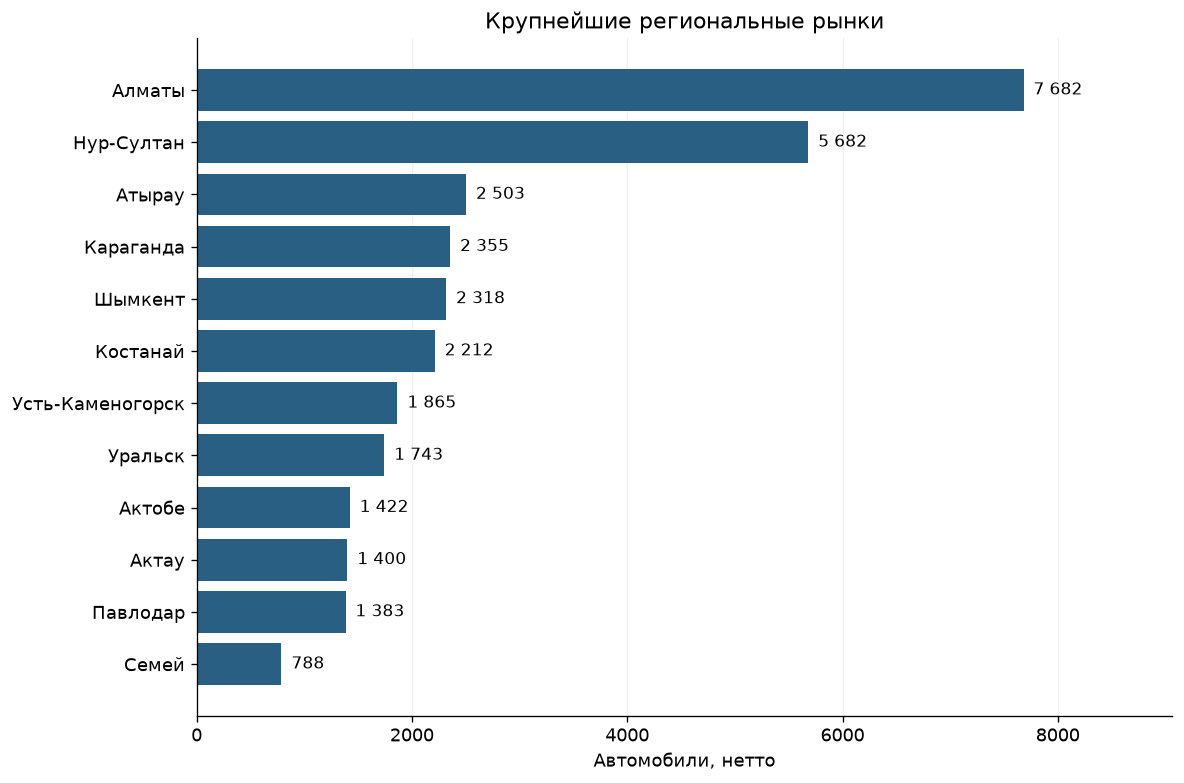

,units,sales_usd,share_pct
segment_2013,,,
Легковые автомобили,15008,"237,043,242.32",43.22
Внедорожники,14047,"420,733,988.61",40.45
Коммерческие автомобили,3487,"110,247,450.64",10.04
Минивэны,1798,"22,213,833.60",5.18
Пикапы,385,"11,459,350.79",1.11


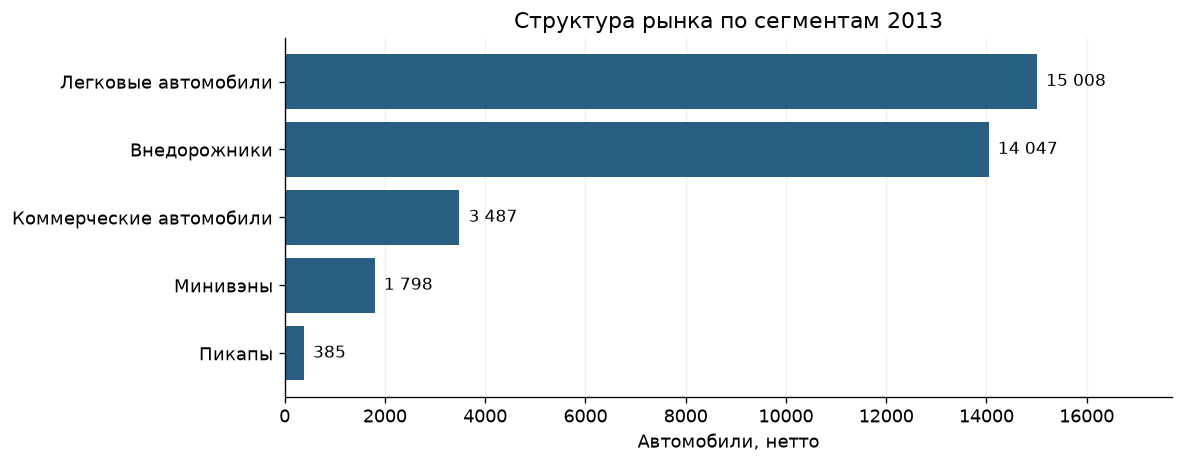

In [5]:
regions = breakdown(market, 'region')
areas = breakdown(market, 'area')
segments = breakdown(market, 'segment_2013')
for name, table in [('market_regions', regions), ('market_areas', areas), ('market_segments', segments)]:
    table.to_csv(f'tables/{name}.csv', encoding='utf-8-sig')
display(areas)
bar(regions.units.head(12), 'Крупнейшие региональные рынки', 'Автомобили, нетто', '04_regions')
display(segments)
bar(segments.units, 'Структура рынка по сегментам 2013', 'Автомобили, нетто', '05_segments')

**Интерпретация.** Алматы и Нур-Султан вместе дают 13 364 автомобиля, около 38.5% рынка. Легковые автомобили и внедорожники вместе составляют около 83.7%; эти два сегмента определяют основную структуру спроса в выборке.

## Топливо, коробка и привод
Неизвестные характеристики отображаются отдельной категорией. Они не исчезают из общего объёма.

,units,sales_usd,share_pct
fuel_type,,,
F,30818,"678,853,062.86",88.75
Неизвестно,2985,"69,791,614.29",8.60
D,903,"51,186,930.59",2.60
HYB,14,"1,096,389.12",0.04
E,5,"769,869.11",0.01


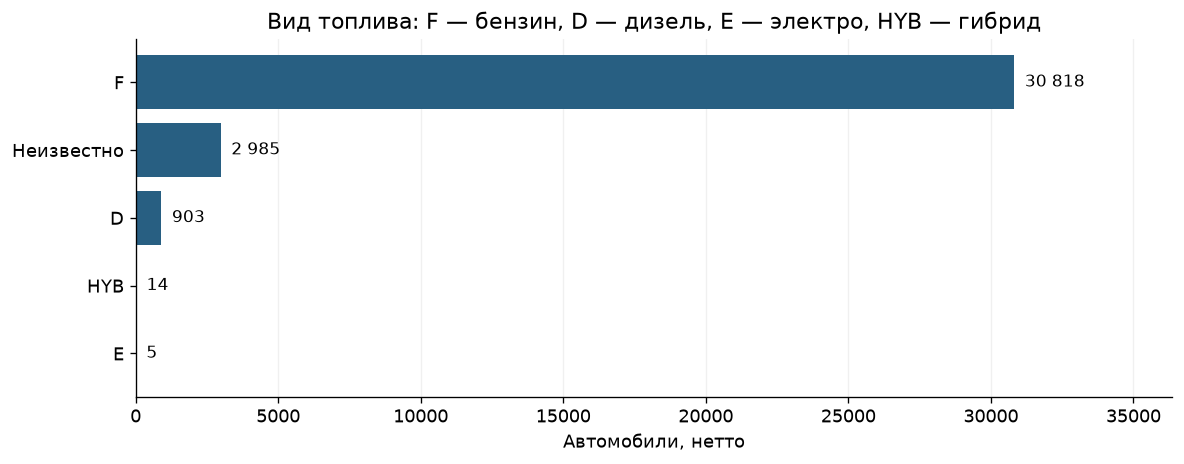

,units,sales_usd,share_pct
transmission,,,
Автомат,17864,"531,803,278.91",51.44
Механика,13904,"195,934,187.03",40.04
Неизвестно,2957,"73,960,400.03",8.52


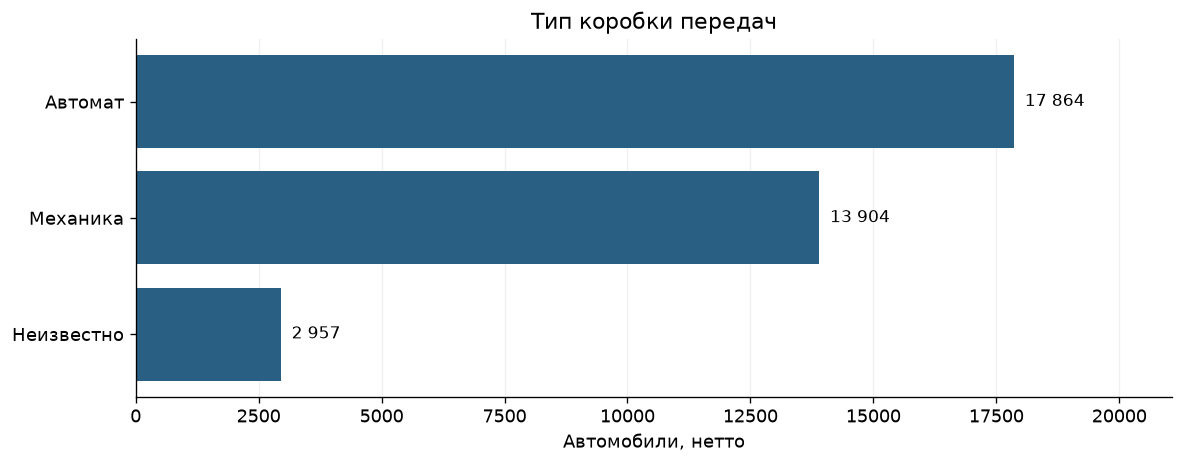

,units,sales_usd,share_pct
drive_type,,,
FWD,13091,"185,738,758.72",37.70
4WD,12499,"398,410,714.19",35.99
2WD,4451,"97,912,914.80",12.82
Неизвестно,3372,"94,560,700.11",9.71
RWD,1312,"25,074,778.15",3.78


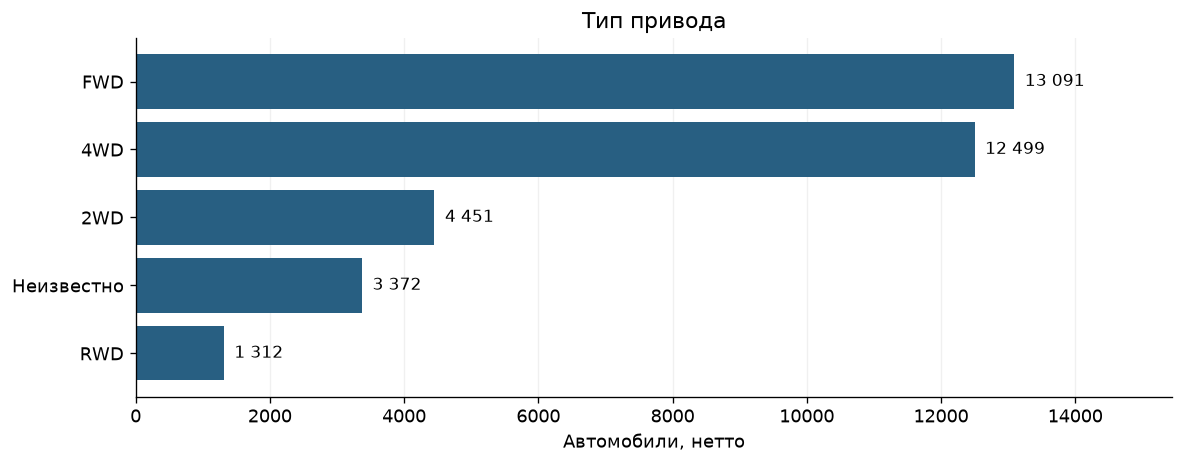

In [6]:
for column, label, name in [('fuel_type', 'Вид топлива: F — бензин, D — дизель, E — электро, HYB — гибрид', '06_fuel'),
                            ('transmission', 'Тип коробки передач', '07_transmission'),
                            ('drive_type', 'Тип привода', '08_drive')]:
    table = breakdown(market, column)
    display(table)
    table.to_csv(f'tables/market_{column}.csv', encoding='utf-8-sig')
    bar(table.units, label, 'Автомобили, нетто', name)

**Интерпретация.** Бензин обозначен у 30 818 автомобилей (88.75% нетто-объёма), тип топлива неизвестен у 2 985. Автомат составляет 51.44%, механика — 40.04%, неизвестная коробка — 8.52%. По приводу доли FWD и 4WD близки: 37.70% и 35.99%. Ещё 12.82% имеют 2WD без указанной оси, поэтому их нельзя механически прибавлять к FWD. Электро- и гибридные автомобили представлены малым числом наблюдений; по ним нельзя делать устойчивые выводы о динамике.

## Распределения цен, объёмов и года выпуска
Веса равны числу положительно проданных автомобилей. На графике цены логарифмическая ось X позволяет показать весь диапазон без удаления дорогих автомобилей.

,count,mean,std,min,25%,50%,75%,95%,max
unit_price_usd,"34,726.00","23,087.41","20,260.95","7,100.00","11,300.00","16,000.00","27,901.68","66,684.76","328,510.97"
engine_l,"31,405.00",2.09,0.88,0.00,1.60,1.69,2.40,3.50,13.00
manufacture_year,"33,837.00","2,018.77",0.45,"2,011.00","2,019.00","2,019.00","2,019.00","2,019.00","2,019.00"


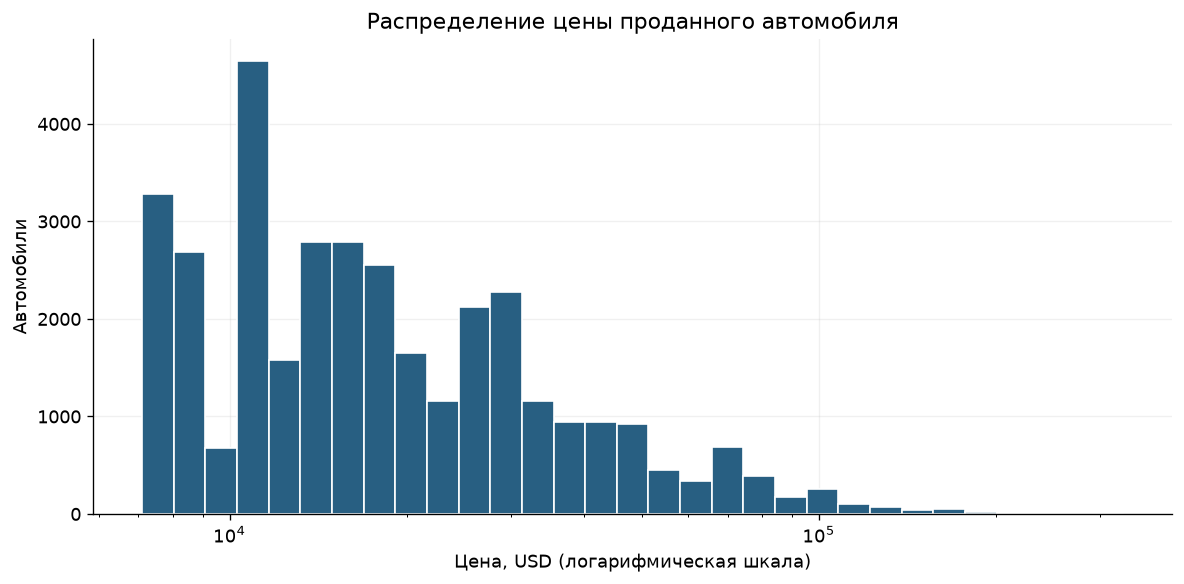

Взвешенная медиана цены: 16,000 USD; 95-й процентиль: 66,685 USD.


In [7]:
distribution = []
for column in ['unit_price_usd', 'engine_l', 'manufacture_year']:
    values = expanded_values(market, column)
    distribution.append(pd.Series(values).describe(percentiles=[.25, .5, .75, .95]).rename(column))
display(pd.DataFrame(distribution))
prices = expanded_values(market, 'unit_price_usd')
fig, ax = plt.subplots()
ax.hist(prices, bins=np.geomspace(prices.min(), prices.max(), 32), color=BLUE, edgecolor='white')
ax.set_xscale('log')
ax.set(title='Распределение цены проданного автомобиля', xlabel='Цена, USD (логарифмическая шкала)', ylabel='Автомобили')
save_figure('09_price_distribution')
print(f'Взвешенная медиана цены: {np.median(prices):,.0f} USD; 95-й процентиль: {np.percentile(prices,95):,.0f} USD.')

**Интерпретация.** Медиана цены составляет 16 000 USD и ниже среднего 23 087 USD: распределение имеет дорогой правый хвост. 95% положительно проданных автомобилей имеют цену не выше примерно 66 685 USD. Дорогие машины сохранены, поскольку высокая цена сама по себе не доказывает ошибку.

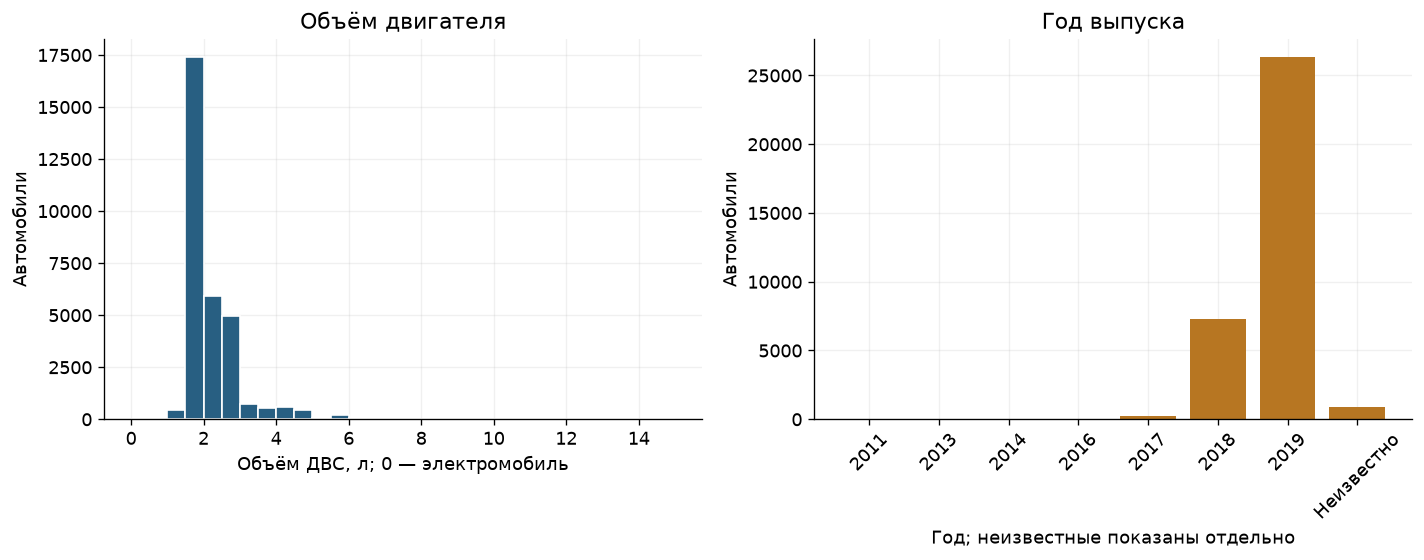

Автомобилей с неизвестным объёмом: 3321
Автомобилей с неизвестным годом: 889


In [8]:
engines = expanded_values(market, 'engine_l')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].hist(engines, bins=np.arange(0, 15.5, .5), color=BLUE, edgecolor='white')
axes[0].set(title='Объём двигателя', xlabel='Объём ДВС, л; 0 — электромобиль', ylabel='Автомобили')
year_table = breakdown(positive, 'manufacture_year')
year_table = year_table.reindex(sorted(year_table.index, key=lambda s: (s == 'Неизвестно', s)))
axes[1].bar(year_table.index.astype(str), year_table.units, color=GOLD)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set(title='Год выпуска', xlabel='Год; неизвестные показаны отдельно', ylabel='Автомобили')
save_figure('10_engine_year')
print('Автомобилей с неизвестным объёмом:', positive.loc[positive.engine_l.isna(), 'quantity'].sum())
print('Автомобилей с неизвестным годом:', positive.loc[positive.manufacture_year.isna(), 'quantity'].sum())

**Интерпретация.** Основная масса известных объёмов сосредоточена около 1.5–2.0 л. Точные значения 1.596 и округлённые 1.6 не принудительно объединены: оба формата могут описывать корректный объём. Автомобили 2019 года выпуска составляют 26 340 из 34 726 положительных продаж (75.85%), 2018 года — 7 258. Год неизвестен у 889, объём — у 3 321 автомобиля. Хвост больших двигателей включает коммерческую технику; нулевой объём означает электропривод.

## Взаимосвязи и неоднородность
Исследуем связь объёма двигателя с ценой отдельно от коммерческой техники и электромобилей. Корреляция — описательная характеристика, а не причинный эффект объёма на цену. Бренд, класс и комплектация могут объяснять часть различий.

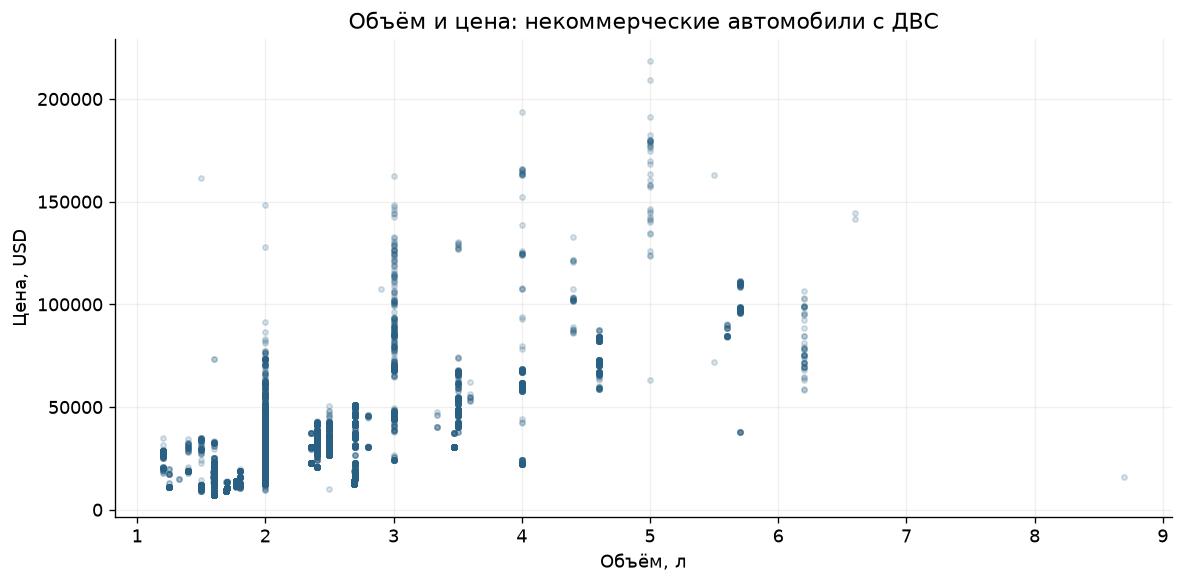

Взвешенная по автомобилям корреляция Пирсона: 0.814; автомобилей: 28,960.
Точка — аналитическая строка, корреляция взвешена по количеству.


,units,revenue,avg_usd
segment_2013,,,
Коммерческие автомобили,3487,"110,247,450.64","31,616.71"
Внедорожники,14047,"420,733,988.61","29,951.88"
Пикапы,385,"11,459,350.79","29,764.55"
Легковые автомобили,15009,"237,078,830.57","15,795.78"
Минивэны,1798,"22,213,833.60","12,354.75"


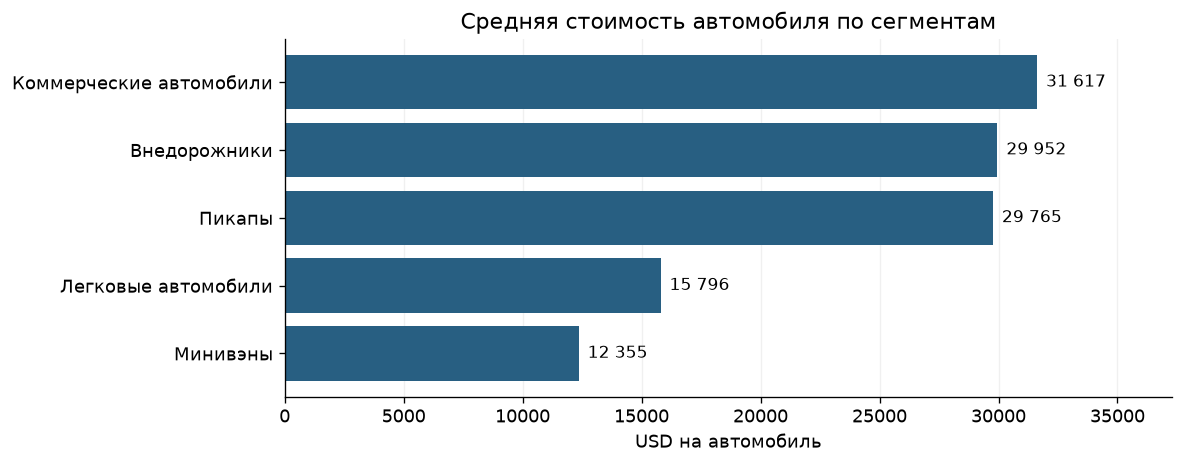

In [9]:
passenger = positive.loc[positive.segment_2013.ne('Коммерческие автомобили') & positive.engine_l.gt(0)].copy()
sample = passenger[['engine_l', 'unit_price_usd', 'quantity']].dropna()
idx = np.repeat(np.arange(len(sample)), sample.quantity.to_numpy(dtype=int))
weighted = sample.iloc[idx]
corr = weighted[['engine_l', 'unit_price_usd']].corr().iloc[0, 1]
fig, ax = plt.subplots()
ax.scatter(sample.engine_l, sample.unit_price_usd, s=10, alpha=.18, color=BLUE, rasterized=True)
ax.set(title='Объём и цена: некоммерческие автомобили с ДВС', xlabel='Объём, л', ylabel='Цена, USD')
save_figure('11_engine_price')
print(f'Взвешенная по автомобилям корреляция Пирсона: {corr:.3f}; автомобилей: {len(weighted):,}.')
print('Точка — аналитическая строка, корреляция взвешена по количеству.')
segment_prices = positive.groupby('segment_2013', observed=True).agg(units=('quantity', 'sum'), revenue=('total_sales_usd', 'sum'))
segment_prices['avg_usd'] = segment_prices.revenue / segment_prices.units
display(segment_prices.sort_values('avg_usd', ascending=False))
bar(segment_prices.avg_usd.sort_values(ascending=False), 'Средняя стоимость автомобиля по сегментам', 'USD на автомобиль', '12_segment_price')

**Интерпретация.** Взвешенная корреляция объёма и цены равна 0.814 для 28 960 некоммерческих автомобилей с известным положительным объёмом. Это сильная положительная описательная связь; причинный эффект не установлен. Средняя цена легкового сегмента около 15 796 USD, внедорожников — 29 952 USD, коммерческой техники — 31 617 USD. Смешение сегментов заметно меняет средний чек.

## Аномалии и чувствительность к удалению дубликатов
Удаление точных повторов задано условиями проекта, но без ID сделок не может считаться доказанным восстановлением фактического рынка. Сравнение ниже ограничивает интерпретацию абсолютных объёмов и долей. Также показываем долю продаж из крупных партий на уровне исходных записей, до агрегации.

In [10]:
raw = load_raw('data/autokz2019_raw.csv')
rows = []
for label, r in [('Без удаления повторов', raw), ('С удалением полных повторов', raw.drop_duplicates())]:
    r = r.loc[r['Регион'].str.strip().str.casefold().ne('экспорт') & r['Количество'].notna()].copy()
    company = r['Компания'].str.strip().replace(COMPANIES)
    mask = company.eq('Mercur Auto')
    rows.append({'scenario': label, 'market_units': r['Количество'].sum(),
                 'mercur_units': r.loc[mask, 'Количество'].sum(),
                 'mercur_share_pct': 100*r.loc[mask, 'Количество'].sum()/r['Количество'].sum()})
sensitivity = pd.DataFrame(rows)
display(sensitivity)
sensitivity.to_csv('tables/dedup_sensitivity.csv', index=False, encoding='utf-8-sig')
detail = pd.read_csv('data/clean_source_records.csv')
domestic_detail = detail.loc[~detail.is_export]
large = domestic_detail.loc[domestic_detail.quantity.ge(10)]
print(f'Партии от 10 автомобилей: {len(large)} записей, {large.quantity.sum():,.0f} автомобилей, {100*large.quantity.sum()/positive.quantity.sum():.1f}% положительных продаж.')

,scenario,market_units,mercur_units,mercur_share_pct
0,Без удаления повторов,"51,955.00",650.00,1.25
1,С удалением полных повторов,"34,725.00",394.00,1.13


Партии от 10 автомобилей: 457 записей, 8,517 автомобилей, 24.5% положительных продаж.


## Вывод этапа
Внутренний рынок в очищенном файле: **34 725 автомобилей нетто**, около **801.70 млн USD**. Экспорт составляет 440 автомобилей и анализируется отдельно. Лидирует Lada; существенную роль играют Hyundai и Toyota. Крупнейшие города — Алматы и Нур-Султан. Максимум месячного объёма приходится на июль, минимум — на январь. Эти результаты описывают только рассматриваемые девять месяцев.

Средняя стоимость положительно проданного автомобиля — около **23 087 USD**. Состав сегментов влияет на цену; поэтому сравнение компаний только по среднему чеку недостаточно. Неизвестные характеристики и чувствительность к дедупликации ограничивают точность общей картины. Крупные партии сохранены; возврат учитывается в нетто-показателях.

**Сверка с заданием:** распределения цены, двигателя и года; бренды, модели, регионы и области, топливо, коробки, привод и сегменты; временная динамика, взаимосвязь и аномалии рассмотрены. Все графики и таблицы основаны на очищенных данных.